## Emotion Classification with RNNs, LSTms, & GRUs

Classifying text into 6 emotions (sadness, joy, love, anger, fear, suprise) by comparing plain recurrent models before building an **Advanced Bidirectional GRU**

### Import Libraries

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


In [2]:
# %pip install datasets

In [3]:
# Dataset load
from datasets import load_dataset

C:\Users\hp\AppData\Roaming\Python\Python313\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Load Dataset

Load the dair-ai/emotion dataset from Hugging Face

In [4]:
emotion_dataset = load_dataset('dair-ai/emotion')
train_text = emotion_dataset['train']['text']
train_label = emotion_dataset['train']['label']

test_text = emotion_dataset['test']['text']
test_label = emotion_dataset['test']['label']

In [5]:
label_names = emotion_dataset['train'].features['label'].names

In [6]:
df_train = pd.DataFrame(
    {
        'text' : train_text,
        'label' : [label_names[i] for i in train_label]
    }
)

df_test = pd.DataFrame(
    {
        'text' : test_text,
        'label' : [label_names[i] for i in test_label]
    }
)

In [7]:
df_train.head()

,text,label
0,i didnt feel humiliated,sadness
1,i can go from feeling so hopeless to so damned...,sadness
2,im grabbing a minute to post i feel greedy wrong,anger
3,i am ever feeling nostalgic about the fireplac...,love
4,i am feeling grouchy,anger


### Exploratory Data Analysis (EDA)


Visualize class distribution across the 6 emotion labels. 

In [8]:
df_train['label'].value_counts()

label
joy         5362
sadness     4666
anger       2159
fear        1937
love        1304
surprise     572
Name: count, dtype: int64

<Axes: xlabel='label', ylabel='count'>

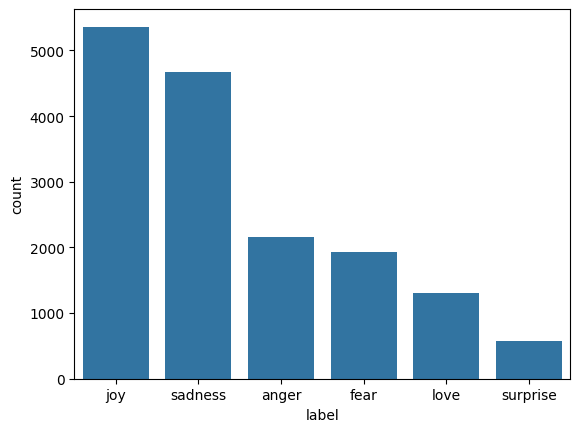

In [9]:
sns.countplot(x='label', data=df_train, order=df_train['label'].value_counts().index)

### Data Preprocessing - Using NLP

Tokenize text, pad sequences to max length 50, and convert labels to NumPy arrays.

In [10]:
# !pip install tensorflow

In [11]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

max_words = 10000

tokenizer = Tokenizer(num_words = max_words, oov_token = '<unk')
tokenizer.fit_on_texts(df_train['text'])

train_sequence = tokenizer.texts_to_sequences(df_train['text'])
test_sequence = tokenizer.texts_to_sequences(df_test['text'])

padded_train_sequence = pad_sequences(train_sequence, maxlen=50, padding='post', truncating='post')
padded_test_sequence = pad_sequences(test_sequence, maxlen=50, padding='post', truncating='post')

padded_train_sequence


train_labels = np.array(train_label)
test_labels = np.array(test_label)

num_classes = len(np.unique(train_labels))
num_classes

print(f"Vocabulary Size: {len(tokenizer.word_index)}")
print((f"Max Sentence Length: {padded_train_sequence.shape[1]}"))


Vocabulary Size: 15213
Max Sentence Length: 50


### Shared Training Utility
Compute balanced class weights to handle dataset skew and setup early stopping.

In [12]:
from sklearn.utils import class_weight

class_weights = class_weight.compute_class_weight(
    class_weight='balanced',
    classes = np.unique(train_labels),
    y = train_labels
)


class_weight_dict = dict(enumerate(class_weights))

In [13]:
from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(
    monitor = 'val_loss',
    patience = 3,
    restore_best_weights = True
)

### Phase 1 - Plain Foundational Models

Train plain (non-bidirectional) Simple RNN, Standard LSTM, and Satndard GRU Models.

tested RNN

In [18]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Embedding, Dense, Dropout, LSTM, GRU

rnn_model = Sequential([
    Embedding(input_dim = max_words, output_dim = 128 , input_length = 50),
    SimpleRNN(units=128, return_sequences=True),
    Dropout(0.5),
    SimpleRNN(units=64),
    Dropout(0.5),
    Dense(units=num_classes, activation='softmax') #Output Layer
])

rnn_model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

In [19]:
rnn_model.fit(
    padded_train_sequence,
    train_labels,
    validation_data=(padded_test_sequence, test_labels),
    epochs = 20,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stopping]
)

rnn_loss, rnn_accuracy = rnn_model.evaluate(padded_test_sequence, test_labels)
print(f"RNN Loss: {rnn_loss}")
print(f"RNN Accuracy: {rnn_accuracy}")

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 43s 77ms/step - accuracy: 0.1594 - loss: 1.9070 - val_accuracy: 0.1090 - val_loss: 1.8128
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 30s 59ms/step - accuracy: 0.1670 - loss: 1.8011 - val_accuracy: 0.2180 - val_loss: 1.7821
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 23s 46ms/step - accuracy: 0.1684 - loss: 1.7790 - val_accuracy: 0.1330 - val_loss: 1.7855
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 41s 45ms/step - accuracy: 0.1719 - loss: 1.7567 - val_accuracy: 0.1180 - val_loss: 1.8202
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 37s 73ms/step - accuracy: 0.1836 - loss: 1.7383 - val_accuracy: 0.1300 - val_loss: 1.7925
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.2180 - loss: 1.7821
RNN Loss: 1.7820563316345215
RNN Accuracy: 0.21799999475479126


RNN accuracy is 0.135

### Model 2 - Standard LSTM

Plain stacked Long Short-Term Memory network.

In [16]:
lstm_model = Sequential([
    Embedding(input_dim = max_words, output_dim = 128 , input_length = 50),
    LSTM(units=128, return_sequences=True),
    Dropout(0.5),
    LSTM(units=64),
    Dropout(0.5),
    Dense(units=num_classes, activation='softmax') #Output Layer
])

lstm_model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

lstm_model.fit(
    padded_train_sequence,
    train_labels,
    validation_data=(padded_test_sequence, test_labels),
    epochs = 20,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stopping]
)

lstm_loss, lstm_accuracy = lstm_model.evaluate(padded_test_sequence, test_labels)
print(f"LSTM Loss: {lstm_loss}")
print(f"LSTM Accuracy: {lstm_accuracy}")

C:\Users\hp\AppData\Roaming\Python\Python313\site-packages\keras\src\layers\core\embedding.py:123: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 95s 178ms/step - accuracy: 0.1414 - loss: 1.7953 - val_accuracy: 0.1105 - val_loss: 1.7830
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 104s 209ms/step - accuracy: 0.1643 - loss: 1.7940 - val_accuracy: 0.0410 - val_loss: 1.7829
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 62s 124ms/step - accuracy: 0.1804 - loss: 1.7941 - val_accuracy: 0.0545 - val_loss: 1.7898
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 50s 100ms/step - accuracy: 0.1797 - loss: 1.7872 - val_accuracy: 0.2370 - val_loss: 1.7911
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 81s 98ms/step - accuracy: 0.2577 - loss: 1.6601 - val_accuracy: 0.3750 - val_loss: 1.5488
Epoch 6/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 48s 95ms/step - accuracy: 0.3927 - loss: 1.3081 - val_accuracy: 0.4700 - val_loss: 1.2117
Epoch 7/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 51s 102ms/step - accuracy: 0.5280 - loss: 0.9771 - val_accuracy: 0.5755 - val_loss: 0.9461
Epoch 8/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 51s 102ms/step - accuracy: 0.6423 - loss: 0.

### Model 3 - Standard GRU

In [17]:
gru_model = Sequential([
    Embedding(input_dim = max_words, output_dim = 128 , input_length = 50),
    GRU(units=128, return_sequences=True),
    Dropout(0.5),
    GRU(units=64),
    Dropout(0.5),
    Dense(units=num_classes, activation='softmax') #Output Layer
])

gru_model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

gru_model.fit(
    padded_train_sequence,
    train_labels,
    validation_data=(padded_test_sequence, test_labels),
    epochs = 20,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stopping]
)

gru_loss, gru_accuracy = gru_model.evaluate(padded_test_sequence, test_labels)
print(f"GRU Loss: {gru_loss}")
print(f"GRU Accuracy: {gru_accuracy}")

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 52s 91ms/step - accuracy: 0.1493 - loss: 1.7969 - val_accuracy: 0.0330 - val_loss: 1.8105
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 47s 93ms/step - accuracy: 0.1355 - loss: 1.7951 - val_accuracy: 0.0820 - val_loss: 1.8029
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 47s 95ms/step - accuracy: 0.1616 - loss: 1.7945 - val_accuracy: 0.1390 - val_loss: 1.7954
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 80s 91ms/step - accuracy: 0.1416 - loss: 1.7930 - val_accuracy: 0.2860 - val_loss: 1.7552
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 82s 91ms/step - accuracy: 0.1441 - loss: 1.7887 - val_accuracy: 0.1145 - val_loss: 1.7694
Epoch 6/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 47s 94ms/step - accuracy: 0.1504 - loss: 1.7721 - val_accuracy: 0.1540 - val_loss: 1.8182
Epoch 7/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 43s 86ms/step - accuracy: 0.1929 - loss: 1.7432 - val_accuracy: 0.0790 - val_loss: 1.8663
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - accuracy: 0.2860 - loss: 1.7552
GRU Loss: 1.7552

### Phase 1 Ranking & Selection

Rank foundational models to pick the best cell for Phase 2

In [20]:
result_df = pd.DataFrame({
    'Model' : ['RNN', 'LSTM', 'GRU'],
    'Test Loss': [rnn_loss, lstm_loss, gru_loss],
    'Test Accuracy': [rnn_accuracy, lstm_accuracy, gru_accuracy]
    }).sort_values(by='Test Accuracy',ascending=False)
result_df

,Model,Test Loss,Test Accuracy
1,LSTM,0.449175,0.8845
2,GRU,1.755215,0.2860
0,RNN,1.782056,0.2180


### Phase 2 - Advanced Bidirectional GRU
Enhance GRU with Bidirectional layers, 3000 embedings, and 0.5 dropout regularization.

### Model 4 - Advanced Stacked Bidirectional GRU

In [21]:
from tensorflow.keras.layers import Bidirectional

BiGRU = Sequential([
    Embedding(input_dim = max_words, output_dim = 300 , input_length = 50),
    Bidirectional(GRU(128, return_sequences=True)),
    Dropout(0.5),
    Bidirectional(GRU(64)),
    Dropout(0.5),
    Dense(num_classes, activation='softmax') #Output Layer
])

BiGRU.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

BiGRU.summary()

C:\Users\hp\AppData\Roaming\Python\Python313\site-packages\keras\src\layers\core\embedding.py:123: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

### Train & Evaluate Advanced Bidirectional GRU

In [22]:

BiGRU.fit(
    padded_train_sequence,
    train_labels,
    validation_data=(padded_test_sequence, test_labels),
    epochs = 20,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stopping]
)

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 152s 253ms/step - accuracy: 0.6043 - loss: 1.0083 - val_accuracy: 0.8980 - val_loss: 0.3004
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 105s 210ms/step - accuracy: 0.9133 - loss: 0.2535 - val_accuracy: 0.9130 - val_loss: 0.2239
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 145s 216ms/step - accuracy: 0.9457 - loss: 0.1510 - val_accuracy: 0.9225 - val_loss: 0.2216
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 108s 216ms/step - accuracy: 0.9539 - loss: 0.1291 - val_accuracy: 0.9215 - val_loss: 0.2424
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 115s 229ms/step - accuracy: 0.9664 - loss: 0.0982 - val_accuracy: 0.9260 - val_loss: 0.2027
Epoch 6/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 106s 212ms/step - accuracy: 0.9749 - loss: 0.0724 - val_accuracy: 0.9215 - val_loss: 0.2548
Epoch 7/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 110s 220ms/step - accuracy: 0.9791 - loss: 0.0601 - val_accuracy: 0.9165 - val_loss: 0.2740
Epoch 8/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 115s 229ms/step - accuracy: 0.9829 -

In [23]:
BiGRU_loss, BiGRU_accuracy = BiGRU.evaluate(padded_test_sequence, test_labels)
print(f"BiGRU Loss: {BiGRU_loss}")
print(f"BiGRU Accuracy: {BiGRU_accuracy}")

63/63 ━━━━━━━━━━━━━━━━━━━━ 4s 51ms/step - accuracy: 0.9260 - loss: 0.2027
BiGRU Loss: 0.20271268486976624
BiGRU Accuracy: 0.9259999990463257


### Overall Evaluation & Bias Analysis

Consolidate test metrics, plot raw & noemalized confusion matrices, and analyze bias.

### Final Model Confusion Matrices (Raw Counts & Normalized %)

63/63 ━━━━━━━━━━━━━━━━━━━━ 10s 96ms/step


<Axes: >

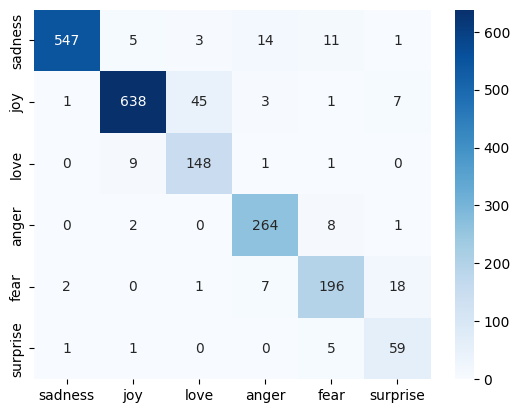

In [24]:
from sklearn.metrics import confusion_matrix

BiGRU_predictions = np.argmax(BiGRU.predict(padded_test_sequence),axis=1)

sns.heatmap(confusion_matrix(test_label, BiGRU_predictions),annot=True, fmt='d', cmap='Blues', xticklabels=label_names, yticklabels=label_names)

### Final Predictions

In [25]:
sample_texts = [
    "I can't believe how happy I am right now, this is amazing!",
    "I feel so alone and hopeless today.",
    "I am furious that they cancelled the trip at the last minute.",
    "I feel terrified when walking down dark alleyways alone.",
    "I was shocked and completely surprised by the unexpected gift!"
]

sample_sequences = tokenizer.texts_to_sequences(sample_texts)
sample_padded_sequences = pad_sequences(sample_sequences, maxlen=50, padding='post', truncating='post')

sample_predictions = np.argmax(BiGRU.predict(sample_padded_sequences), axis=1)

for i in range(len(sample_texts)):
  print(f'Text: {sample_texts[i]}\nPredicted Emotion: {label_names[sample_predictions[i]]}')

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
Text: I can't believe how happy I am right now, this is amazing!
Predicted Emotion: surprise
Text: I feel so alone and hopeless today.
Predicted Emotion: sadness
Text: I am furious that they cancelled the trip at the last minute.
Predicted Emotion: anger
Text: I feel terrified when walking down dark alleyways alone.
Predicted Emotion: fear
Text: I was shocked and completely surprised by the unexpected gift!
Predicted Emotion: surprise


### Save Model & Tokenizer
Export trained model and tokenizer artifacts for API deployment.

In [26]:
import os
import pickle

model_dir = 'Artifacts'
os.makedirs(model_dir, exist_ok=True)

#Save our BiGRU Model
BiGRU.save(os.path.join(model_dir, 'BiGRU_Modle.keras'))

#Save the tokenizer model
with open(os.path.join(model_dir, 'tokenizer.pkl'), 'wb') as file:
  pickle.dump(tokenizer, file)